# Test B — 어선 이상항적 분석 과정

이 노트북은 제출 패키지 `deliverables/testb_system_20261106/`의 분석 과정을 단계별로 실행합니다.
`src/run_analysis.py`가 한 번에 수행하는 일을 여섯 단계로 나누고, 각 단계에서 무엇이 입력되고
무엇이 결정되는지 확인합니다.

| 단계 | 내용 |
| --- | --- |
| 1 | 시간별 항적 요약 입력을 적재하고 범위를 확인 |
| 2 | 고정 참조자료의 해시를 검증하고 적재 |
| 3 | 한 척을 대상으로 세 구성점수가 만들어지는 과정을 확인 |
| 4 | 100척 전체를 재계산하고 보관된 결과와 전수 대조 |
| 5 | 선박별 검토 후보를 선정하고 근거를 정리 |
| 6 | 점수 분포와 개별 사례를 시각화 |

**실행 요건.** Python 3.13, `requirements.txt`의 numpy·pandas·pyarrow·scipy, 그래프용 matplotlib.
CPU만 사용하며 외부 API를 호출하지 않습니다. 4단계의 전체 재계산에 40초 남짓 걸립니다
(실행마다 변동하며, 같은 계산을 `src/run_analysis.py`로 실행하면 33.4초입니다).

이 노트북은 입력과 참조자료를 읽기만 하고 수정하지 않습니다. 파일을 새로 쓰지 않으므로
`results/` 아래에 결과 폴더를 만들지 않습니다.

## 0. 환경 준비

In [1]:
import json
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow
import pyarrow.parquet as pq

PACKAGE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PACKAGE / "config.json").is_file(), f"패키지 루트를 찾을 수 없음: {PACKAGE}"
sys.path.insert(0, str(PACKAGE / "src"))

import frozen_baseline as fb
import run_analysis as ra

print("패키지 경로:", PACKAGE)
print("Python:", sys.version.split()[0])
print("numpy / pandas / pyarrow:", np.__version__, pd.__version__, pyarrow.__version__)

패키지 경로: D:\obsidian\claude\obsidian_export\DATA AI SHIPPING\deliverables\testb_system_20261106
Python: 3.13.3
numpy / pandas / pyarrow: 2.2.5 2.2.3 24.0.0


## 1. 입력 데이터 적재

입력은 1시간 구간마다 한 행입니다. 원본 항적(MultiLineString)은 전처리 단계에서
다음 요약값으로 바뀌어 들어옵니다.

- `cen_lon`, `cen_lat` — 그 1시간 항적의 기하 중심점
- `len_m` — 부분선 전체 길이
- `bbox_m` — 경계상자 크기
- `ts` — 정수 시간키, `rfid_time` — 원본 시각 문자열의 시(hour)
- `source_ordinal` — 원본 행 순서. 동점 처리와 대조에 사용

좌표별 시각은 원본에 없으므로 이 값에서 속력이나 침로를 복원하지 않습니다.

In [2]:
observations = pq.read_table(PACKAGE / "inputs/observations.parquet",
                             columns=list(ra.INPUT_COLUMNS)).to_pandas()
roster = pd.read_csv(PACKAGE / "inputs/roster.csv", dtype={"rfid_id": str})["rfid_id"].tolist()

print(f"행 수: {len(observations):,} / 선박 수: {observations.rfid_id.nunique()}")
print(f"관측 구간: {ra.label(observations.ts.min())} ~ {ra.label(observations.ts.max())}")
observations.head()

행 수: 46,705 / 선박 수: 100
관측 구간: 20250101 0 ~ 20250630 23


,rfid_id,ts,source_ordinal,rfid_time,len_m,bbox_m,cen_lon,cen_lat,n_coords
0,34400012,482250,116938,18,1299.067592,1295.809599,131.146713,37.224913,11
1,34400012,482253,118569,21,13897.537563,13861.293147,130.778429,37.354086,106
2,34400012,482254,119091,22,12080.421771,12041.641533,130.643855,37.394233,108
3,34400012,482255,119579,23,12411.662055,12394.236572,130.507052,37.445275,78
4,34400012,482256,125698,0,14824.738247,14812.245689,130.355664,37.513240,55


In [3]:
per_vessel = observations.groupby("rfid_id").size()
print("선박별 관측 수 — 최소 %d행 / 중위 %d행 / 최대 %d행" % (
    per_vessel.min(), per_vessel.median(), per_vessel.max()))
print("관측 24행 미만 선박:", int((per_vessel < fb.MIN_HIST_FOR_CHANGE).sum()), "척")
observations[["len_m", "bbox_m", "cen_lon", "cen_lat"]].describe().T

선박별 관측 수 — 최소 1행 / 중위 165행 / 최대 3413행
관측 24행 미만 선박: 25 척


,count,mean,std,min,25%,50%,75%,max
len_m,46705.0,6663.145395,13870.819257,0.000000,13.746360,442.859405,6494.748220,154997.509145
bbox_m,46705.0,2032.628162,3912.749743,0.000000,6.434930,162.339655,2091.359255,30829.703463
cen_lon,46705.0,127.881992,1.593807,124.904575,126.333726,127.967463,129.286286,132.035649
cen_lat,46705.0,35.814861,1.513472,30.774838,34.569003,35.177689,37.057838,38.537247


선박별 관측 수의 편차가 큽니다. 1행만 있는 선박과 3,000행이 넘는 선박이 같은 입력에 섞여 있고,
이 차이가 뒤에서 `s_change`를 계산할 수 있는지를 가릅니다.

## 2. 고정 참조자료 검증과 적재

이 시스템은 가중치를 학습하지 않고, 2026년 학습 구간에서 미리 산출한 참조분포를 고정해 씁니다.
참조자료가 바뀌면 점수도 바뀌므로 실행 전에 `config.json`에 기록된 SHA-256과 대조합니다.

In [4]:
config = json.loads((PACKAGE / "config.json").read_text(encoding="utf-8"))
hashes = ra.validate_manifest(config, PACKAGE)   # 해시 불일치면 여기서 예외가 발생한다
print(f"해시 검증 통과: {len(hashes)}개 파일")
print("실행 방식:", config["mode"], "| 학습 활성화:", config["training_enabled"], "| 임계값:", config["threshold"])

해시 검증 통과: 11개 파일
실행 방식: frozen_baseline_reproduction | 학습 활성화: False | 임계값: None


In [5]:
nearest, fine, coarse, norm_gap, norm_jump, reference_meta = fb.load_references(PACKAGE / "references")
print(json.dumps(reference_meta, indent=2, ensure_ascii=False))
print()
print("밀도 격자 — 세밀(0.01도) %d칸 / 조대(0.05도) %d칸" % (len(fine), len(coarse)))
print("1시간 간격의 공백 분위:", round(float(norm_gap(1.0)), 4))
print("100m 이동의 거리 분위:", round(float(norm_jump(100.0)), 4))

{
  "gap": {
    "n_ref": 3879693,
    "p50": 1.0
  },
  "jump": {
    "n_ref": 3879693,
    "p50": 85.72352634799219
  },
  "harbor_count": 77
}

밀도 격자 — 세밀(0.01도) 102053칸 / 조대(0.05도) 9174칸
1시간 간격의 공백 분위: 0.8991
100m 이동의 거리 분위: 0.507


`norm_gap(1.0)`이 0.9 근처라는 점을 눈여겨볼 필요가 있습니다. 1시간 간격은 이 데이터에서
가장 흔한 정상 간격인데도 분위수가 높게 나옵니다. 참조분포의 중위수가 1시간이라서
`searchsorted`가 같은 값의 오른쪽 경계를 반환하기 때문입니다. 결과적으로 연속 관측 구간에서는
`s_gap`의 시간항이 거의 상수가 되고, 후보 간의 `s_gap` 차이는 중심점 이동 거리항이 만듭니다.
이 동작은 보고서의 한계 항목으로 기록되어 있습니다.

## 3. 한 척에서 점수가 만들어지는 과정

전체 재계산 전에 한 척만 돌려 세 성분이 어떻게 채워지는지 확인합니다.
`score_vessel`은 한 선박의 관측을 시간순으로 훑으면서 다음을 누적합니다.

- **`s_zone`** = 0.5 × (과거 방문 격자까지의 거리 / 20km, 최대 1) + 0.5 × (학습 밀도 희소도)
- **`s_change`** = 과거 24행 이상 쌓인 뒤, 길이·형상비의 robust z와 상태 빈도 변화의 평균
- **`s_gap`** = 0.5 × 공백 시간 분위 + 0.5 × 중심점 이동 거리 분위

종합점수는 계산된 성분들의 평균을 `[1e-6, 1]`로 절단한 값입니다.

In [6]:
sample_rfid = per_vessel.idxmax()        # 관측이 가장 많은 선박
vessel = (observations[observations.rfid_id == sample_rfid]
          .sort_values(["ts", "rfid_time", "source_ordinal"], kind="stable")
          .reset_index(drop=True))
scored_one = fb.score_vessel(vessel, nearest, None, fine, coarse, norm_gap, norm_jump)

print(f"선박 {sample_rfid}: {len(scored_one):,}행")
scored_one[["ts", "state", "len_m", "bbox_m", "s_zone", "s_change", "s_gap", "score"]].head(30)

선박 36002764: 3,413행


,ts,state,len_m,bbox_m,s_zone,s_change,s_gap,score
0,482136,정박정지,7.271300,5.959870,0.000000,NaN,NaN,0.000001
1,482137,정박정지,5.891181,3.362645,0.000000,NaN,0.542176,0.271088
2,482138,정박정지,1.667924,1.297274,0.000000,NaN,0.565548,0.282774
3,482139,저속굴곡,6574.738793,1694.164797,0.014667,NaN,0.727330,0.370998
4,482140,저속굴곡,20028.080679,9886.998583,0.153899,NaN,0.920070,0.536985
5,482141,저속굴곡,4798.336648,1238.834855,0.088408,NaN,0.899058,0.493733
6,482142,저속굴곡,1573.172348,616.020717,0.014035,NaN,0.790584,0.402309
7,482143,저속굴곡,13181.471980,4805.832988,0.000000,NaN,0.796320,0.398160
8,482144,저속굴곡,22325.560216,6077.266578,0.020817,NaN,0.928414,0.474616
9,482145,정박정지,20.503943,12.858668,0.000000,NaN,0.788671,0.394335


In [7]:
first_change = scored_one.s_change.first_valid_index()
print(f"s_change가 처음 계산된 행: {first_change}번째 (임계 {fb.MIN_HIST_FOR_CHANGE}행)")
print(f"s_gap 결측: {int(scored_one.s_gap.isna().sum())}행 (첫 관측은 직전 비교 대상이 없다)")
print()
print("상태 분포")
print(scored_one.state.value_counts().to_string())

s_change가 처음 계산된 행: 24번째 (임계 24행)
s_gap 결측: 1행 (첫 관측은 직전 비교 대상이 없다)

상태 분포
state
정박정지    1754
저속굴곡    1645
이동        14


첫 행은 `s_zone`만으로 종합점수를 받습니다. 즉 같은 0.5라는 점수가 세 성분을 모두 쓴 결과일 수도,
한 성분만 쓴 결과일 수도 있습니다. 그래서 뒤의 후보 목록에서는 점수와 함께 성분 수와
과거 관측 수를 항상 같이 출력합니다.

## 4. 100척 전체 재계산과 전수 대조

보관된 결과를 그대로 읽어오는 대신, 입력과 참조자료에서 점수를 다시 계산해
보관본과 비교합니다. 40초 남짓 걸립니다.

In [8]:
import time

started = time.perf_counter()
frames = []
for number, rfid in enumerate(roster, 1):
    one = (observations[observations.rfid_id == rfid]
           .sort_values(["ts", "rfid_time", "source_ordinal"], kind="stable")
           .reset_index(drop=True))
    frames.append(fb.score_vessel(one, nearest, None, fine, coarse, norm_gap, norm_jump))
    if number % 25 == 0:
        print(f"  {number}/100척 완료", flush=True)
scored = pd.concat(frames, ignore_index=True)
print(f"재계산 완료: {len(scored):,}행 / {time.perf_counter() - started:.1f}초")

  25/100척 완료


  50/100척 완료


  75/100척 완료


  100/100척 완료


재계산 완료: 46,705행 / 36.4초


In [9]:
stored = pq.read_table(PACKAGE / "inputs/stored_expected.parquet").to_pandas()
parity = ra.compare_rows(scored, stored)
print(json.dumps(parity, indent=2, ensure_ascii=False))

{
  "rows_compared": 46705,
  "numeric_max_abs_diff": {
    "s_zone": 0.0,
    "s_change": 0.0,
    "s_gap": 0.0,
    "score": 0.0
  },
  "nan_mask_mismatches": {
    "s_zone": 0,
    "s_change": 0,
    "s_gap": 0,
    "score": 0
  },
  "numeric_exact": {
    "s_zone": true,
    "s_change": true,
    "s_gap": true,
    "score": true
  },
  "state_mismatches": 0,
  "all_row_checks_passed": true
}


네 개 점수 컬럼의 최대 절대차가 0.0이고, 결측 위치와 상태 문자열도 모두 일치합니다.
이는 **계산 재현성**의 확인입니다. 사고 정답에 대한 정확도를 측정한 것은 아닙니다.

## 5. 검토 후보 선정

선박별로 전체 기간의 최고점을 뽑습니다. 동점이면 원본 `source_ordinal`이 작은 행을 택합니다.
후보 행에는 점수뿐 아니라 판단에 필요한 맥락을 함께 싣습니다.

In [10]:
candidates, sample_cases = ra.candidate_records(scored, stored, roster)
cand = pd.DataFrame(candidates)

view = ["rank_by_peak", "rfid_id", "lead_label", "score", "s_zone", "s_change", "s_gap",
        "dominant_component", "component_count", "prior_observation_count", "n_observations"]
cand.sort_values("rank_by_peak")[view].head(10)

,rank_by_peak,rfid_id,lead_label,score,s_zone,s_change,s_gap,dominant_component,component_count,prior_observation_count,n_observations
72,1,32300727,20250101 22,0.922847,0.897197,NaN,0.948497,s_gap,2,9,1406
13,2,32000047,20250604 12,0.849537,0.969880,0.631370,0.947360,s_zone,3,1516,1718
0,3,34400012,20250110 23,0.816259,0.833333,0.656198,0.959247,s_gap,3,45,915
9,4,36002764,20250614 10,0.785871,0.587736,0.822671,0.947205,s_gap,3,3037,3413
68,5,36010232,20250611 7,0.771785,0.602987,0.765453,0.946914,s_gap,3,353,451
1,6,36201616,20250113 13,0.767149,0.500000,0.852302,0.949144,s_gap,3,25,601
55,7,32300322,20250226 13,0.765429,0.500000,0.797475,0.998811,s_gap,3,165,1742
15,8,32200526,20250526 7,0.763882,0.453398,0.902411,0.935837,s_gap,3,308,1089
27,9,32100061,20250102 22,0.742268,0.360217,0.924758,0.941830,s_gap,3,46,1837
23,10,31010758,20250101 13,0.731756,0.521081,NaN,0.942432,s_gap,2,8,1158


In [11]:
print("후보 점수 — 중위 %.6f / 최대 %.6f / 최소 %.6f" % (
    cand.score.median(), cand.score.max(), cand.score.min()))
print()
print("과거 관측 24행 미만:", int((cand.prior_observation_count < fb.MIN_HIST_FOR_CHANGE).sum()), "/ 100척")
print("성분 3개를 모두 쓰지 못한 후보:", int((cand.component_count < 3).sum()), "/ 100척")
print("과거 관측이 전혀 없는 후보:", int((cand.prior_observation_count == 0).sum()), "/ 100척")
print()
print("최대 성분 분포")
print(cand.dominant_component.value_counts().to_string())
print()
print("직전 정확 시각의 관측 존재 여부")
for offset in (3, 2, 1):
    observed = int((cand[f"reference{offset}_status"] == "observed").sum())
    print(f"  t-{offset}시간: {observed}/100척")

후보 점수 — 중위 0.548824 / 최대 0.922847 / 최소 0.000001

과거 관측 24행 미만: 39 / 100척
성분 3개를 모두 쓰지 못한 후보: 39 / 100척
과거 관측이 전혀 없는 후보: 6 / 100척

최대 성분 분포
dominant_component
s_gap       88
s_zone       7
s_change     5

직전 정확 시각의 관측 존재 여부
  t-3시간: 33/100척
  t-2시간: 38/100척
  t-1시간: 58/100척


후보 100척 가운데 39척은 그 시점까지의 과거 관측이 24행에 못 미칩니다. 이 후보들의 높은 점수는
"평소와 달랐다"기보다 "비교할 평소가 아직 없다"에 가깝습니다. 직전 1시간에 관측이 있는 후보도
58척뿐이어서, 사고 전후의 변화를 보려 해도 참조할 행이 없는 경우가 많습니다.

이 수치들을 후보 목록에 그대로 노출하는 것이 이 시스템의 설계 의도입니다.

## 6. 시각화

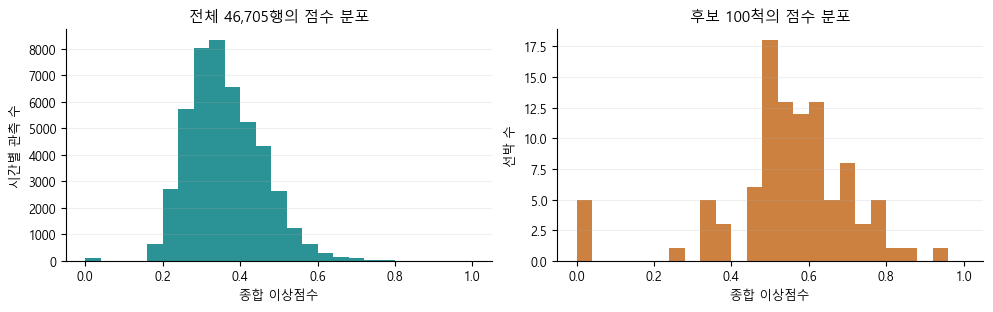

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

font_path = Path("C:/Windows/Fonts/malgun.ttf")
if font_path.is_file():
    plt.rcParams["font.family"] = FontProperties(fname=str(font_path)).get_name()
plt.rcParams.update({"axes.unicode_minus": False, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
TEAL, ORANGE = "#067f83", "#c46b20"

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].hist(scored.score.dropna(), bins=np.linspace(0, 1, 26), color=TEAL, alpha=.85)
axs[0].set(xlabel="종합 이상점수", ylabel="시간별 관측 수", title="전체 46,705행의 점수 분포")
axs[1].hist(cand.score, bins=np.linspace(0, 1, 26), color=ORANGE, alpha=.85)
axs[1].set(xlabel="종합 이상점수", ylabel="선박 수", title="후보 100척의 점수 분포")
for ax in axs:
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

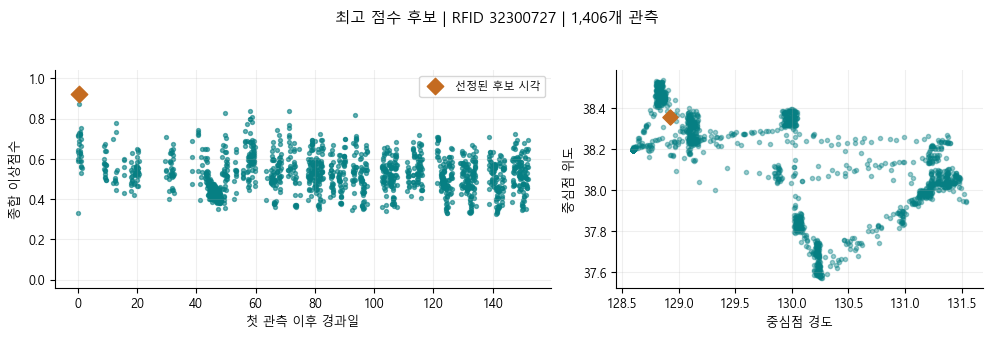

후보 시각: 20250101 22 / 종합점수 0.922847
구성점수: s_zone=0.8971966331913308 s_change=nan s_gap=0.948497213568187
그 시점까지의 과거 관측: 9행


In [13]:
top = cand.sort_values("rank_by_peak").iloc[0]
g = (scored[scored.rfid_id == top.rfid_id]
     .sort_values(["ts", "source_ordinal"]).reset_index(drop=True))
elapsed_days = (g.ts - g.ts.min()) / 24.0

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.35, 1]})
axs[0].scatter(elapsed_days, g.score, s=8, color=TEAL, alpha=.6)
axs[0].scatter([(top.lead_ts - g.ts.min()) / 24.0], [top.score], s=70, marker="D",
               color=ORANGE, zorder=4, label="선정된 후보 시각")
axs[0].set(xlabel="첫 관측 이후 경과일", ylabel="종합 이상점수", ylim=(-.04, 1.04))
axs[0].legend(fontsize=8)
axs[1].scatter(g.cen_lon, g.cen_lat, s=9, color=TEAL, alpha=.4)
axs[1].scatter([top.cen_lon], [top.cen_lat], s=60, marker="D", color=ORANGE)
axs[1].set(xlabel="중심점 경도", ylabel="중심점 위도")
axs[1].ticklabel_format(useOffset=False, style="plain")
for ax in axs:
    ax.grid(alpha=.2)
fig.suptitle(f"최고 점수 후보 | RFID {top.rfid_id} | {int(top.n_observations):,}개 관측", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .93))
plt.show()

print(f"후보 시각: {top.lead_label} / 종합점수 {top.score:.6f}")
print(f"구성점수: s_zone={top.s_zone} s_change={top.s_change} s_gap={top.s_gap}")
print(f"그 시점까지의 과거 관측: {int(top.prior_observation_count)}행")

오른쪽 그림은 시간별 중심점의 산점도입니다. 점을 선으로 잇지 않은 것은 관측 사이의 경로가
데이터에 없기 때문입니다.

## 정리

이 노트북에서 확인한 것은 다음 네 가지입니다.

1. 입력은 1시간 단위 기하 요약이며, 선박별 관측 수의 편차가 매우 큽니다.
2. 점수는 고정된 참조분포와 선박 자신의 이력에서 계산되고, 참조자료의 해시가 실행 전에 검증됩니다.
3. 100척 46,705행을 다시 계산한 결과가 보관본과 전 컬럼에서 일치합니다.
4. 후보 100척 중 39척은 `s_change`를 쓸 수 없는 상태이며, 이 정보가 점수와 함께 출력됩니다.

사고 탐지 성능은 별도 개발 자료에서 측정했고 현재 ±6시간 내 top-1 적중은 최대 4/100입니다.
따라서 이 점수는 사고 판정값이 아니라 검토 우선순위 지표이며, 임계값 기반 자동 경보는
구현하지 않았습니다. 측정 수치와 미확인 항목은 제출 README의 "성능 지표와 한계" 절에 정리되어 있습니다.

전체 과정을 한 번에 실행하고 산출물을 파일로 저장하려면 패키지 루트에서 다음을 실행합니다.

```powershell
python src/run_analysis.py --output results/reproduction_new
```